# 1. Introducción

Este capítulo plantea el tipo de problemas que trata el libro y la razón por la que hacen falta métodos aproximados para resolverlos. Presenta los tres problemas que sirven de ejemplo en los capítulos siguientes, la mochila, las $n$ reinas y el agente viajero, y mide cuánto tarda la enumeración exhaustiva de sus soluciones a medida que crece el tamaño de la instancia. Termina con el muestreo aleatorio, la estrategia más simple que no enumera todo, y con un mapa del libro.

## Problemas de optimización

Un problema de optimización pide escoger, entre un conjunto de alternativas, la que hace mejor un criterio. Las alternativas se describen con variables de decisión $x$, el criterio es una función objetivo $f$ y las restricciones definen el conjunto $X$ de alternativas permitidas, llamadas soluciones factibles. En su forma general, el problema es

$$\min_{x \in X} f(x),$$

y un problema de maximización se escribe igual con $-f$ en lugar de $f$. Una solución $x^*$ es un óptimo global si $f(x^*) \le f(x)$ para toda $x \in X$.

Cuando las variables toman valores reales, el problema es continuo, como la minimización de la función de Rosenbrock del capítulo 7. Cuando las soluciones son objetos discretos, como subconjuntos, permutaciones o asignaciones, el problema es combinatorio. En un problema combinatorio el conjunto $X$ es finito, de modo que, en principio, basta revisar todas las soluciones para encontrar la mejor. La dificultad está en que el número de soluciones crece muy rápido con el tamaño del problema, y este capítulo lo cuantifica.

## Métodos exactos, heurísticas y metaheurísticas

Un método exacto garantiza que la solución que entrega es un óptimo global. La enumeración exhaustiva es el más simple; la ramificación y acotamiento (*branch and bound*) y la programación dinámica evitan revisar todas las soluciones, pero en muchos problemas combinatorios su tiempo de cómputo, en el peor caso, también crece de forma exponencial con el tamaño de la instancia. Para instancias pequeñas o con estructura favorable, los métodos exactos son la mejor opción, porque además de la solución entregan la certeza de que es óptima.

Una heurística es un procedimiento diseñado para un problema concreto que encuentra una solución buena en poco tiempo, sin garantizar que sea óptima. Construir una ruta yendo siempre a la ciudad más cercana o llenar una mochila con los objetos de mayor valor por unidad de peso son heurísticas. Una metaheurística es una estrategia general que guía a una o varias heurísticas para explorar el espacio de soluciones más allá de lo que cada una alcanza por sí sola, en particular para no quedarse en la primera solución que ya no se puede mejorar con cambios pequeños. La misma metaheurística se aplica a problemas distintos, adaptando la representación de la solución y los movimientos que la modifican.

Usar una heurística o una metaheurística es aceptar un intercambio entre la calidad de la solución y el tiempo de cómputo. Tiene sentido cuando el problema es demasiado grande para un método exacto, cuando la función objetivo sale de una simulación o de un modelo de aprendizaje de máquina y no tiene una forma que un método exacto pueda aprovechar, o cuando hace falta una buena solución en un tiempo fijo, aunque no sea la óptima.

In [1]:
import itertools
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt

## Tres problemas que recorren el libro

Los capítulos 1, 3, 4, 5, 6 y 9 usan las mismas instancias de tres problemas clásicos, de modo que los resultados de un método se pueden comparar con los de otro. La celda siguiente las genera con una semilla fija.

### El problema de la mochila

Hay $n$ objetos; el objeto $i$ pesa $w_i$ y vale $v_i$, y la mochila soporta un peso máximo $C$. El problema es escoger los objetos que maximizan el valor total sin pasar de la capacidad,

$$\max \sum_{i=1}^{n} v_i\, x_i \quad \text{s. a.} \quad \sum_{i=1}^{n} w_i\, x_i \le C, \qquad x_i \in \{0, 1\},$$

donde $x_i = 1$ si el objeto $i$ entra a la mochila. Una solución es un vector binario de longitud $n$, así que hay $2^n$ soluciones, factibles o no. La instancia del libro tiene 20 objetos, con pesos enteros entre 1 y 30, valores enteros entre 1 y 50 y una capacidad igual al 40 % del peso total.

### El problema de las $n$ reinas

Hay que ubicar $n$ reinas en un tablero de $n \times n$ sin que ninguna ataque a otra, es decir, sin que dos de ellas compartan fila, columna o diagonal. Como en el capítulo 7, una solución se representa como una permutación $s$ de $\{0, \dots, n-1\}$, en la que el índice es la columna y el valor $s_i$ es la fila de la reina de esa columna. Así ninguna fila ni columna se repite, y el problema se convierte en minimizar el número de pares de reinas que se atacan en diagonal,

$$c(s) = \left|\{(i, j) : i < j,\ |s_i - s_j| = |i - j|\}\right|.$$

Una permutación con $c(s) = 0$ es una solución del problema. Hay $n!$ permutaciones. El libro usa tableros de $8 \times 8$, que se pueden enumerar, y de $30 \times 30$, que no.

### El problema del agente viajero

Un agente debe visitar $n$ ciudades, cada una una sola vez, y volver a la ciudad de partida recorriendo la menor distancia posible. Si $d_{ij}$ es la distancia entre las ciudades $i$ y $j$ y la permutación $\pi$ da el orden de visita, la longitud del recorrido es

$$L(\pi) = \sum_{k=1}^{n-1} d_{\pi_k \pi_{k+1}} + d_{\pi_n \pi_1}.$$

Como el recorrido es un ciclo, se puede fijar la ciudad de partida, y como las distancias son simétricas, recorrer el ciclo en un sentido o en el otro da la misma longitud. Por eso hay $(n-1)!/2$ recorridos distintos. La instancia del libro tiene 50 ciudades ubicadas al azar en un cuadrado de $100 \times 100$, con distancias euclidianas; las 10 primeras forman una instancia pequeña que se puede enumerar.

In [2]:
np.random.seed(42)
random.seed(42)

# Mochila: 20 objetos
N_OBJETOS = 20
pesos = np.random.randint(1, 31, size=N_OBJETOS)
valores = np.random.randint(1, 51, size=N_OBJETOS)
capacidad = int(0.4 * pesos.sum())

# Agente viajero: 50 ciudades en un cuadrado de 100 x 100
N_CIUDADES = 50
ciudades = np.random.uniform(0, 100, size=(N_CIUDADES, 2))
distancias = np.sqrt(((ciudades[:, None, :] - ciudades[None, :, :]) ** 2).sum(axis=2))

print(f"Mochila: {N_OBJETOS} objetos, peso total {pesos.sum()}, capacidad {capacidad}")
print(f"Pesos:   {pesos}")
print(f"Valores: {valores}")
print(f"Agente viajero: {N_CIUDADES} ciudades")

Mochila: 20 objetos, peso total 321, capacidad 128
Pesos:   [ 7 20 29 15 11  8 29 21  7 26 19 23 11 11 24 21  4  8 24  3]
Valores: [22  2 24 44 30 38  2 21 33 12 22 44 25 49 27 42 28 16 15 47]
Agente viajero: 50 ciudades


Las tres funciones siguientes evalúan una solución de cada problema. La de la mochila devuelve el valor total de los objetos elegidos y `None` si la solución pasa de la capacidad.

In [3]:
def valor_mochila(x, pesos, valores, capacidad):
    """Valor total de la selección x, o None si excede la capacidad."""
    if np.dot(x, pesos) > capacidad:
        return None
    return int(np.dot(x, valores))


def conflictos(s):
    """Número de pares de reinas que se atacan en diagonal."""
    n = len(s)
    return sum(1 for i in range(n) for j in range(i + 1, n) if abs(s[i] - s[j]) == j - i)


def longitud_recorrido(ruta, distancias):
    """Longitud del ciclo que visita las ciudades en el orden de ruta."""
    return sum(distancias[ruta[k], ruta[(k + 1) % len(ruta)]] for k in range(len(ruta)))

## La explosión combinatoria

La tabla siguiente compara el número de soluciones de cada problema para varios tamaños.

In [4]:
print(f"{'n':>5} | {'mochila 2^n':>12} | {'reinas n!':>12} | {'viajero (n-1)!/2':>16}")
print("-" * 54)
for n in [5, 10, 20, 30, 50, 100]:
    print(f"{n:>5} | {2.0 ** n:>12.3e} | {float(math.factorial(n)):>12.3e} | "
          f"{math.factorial(n - 1) / 2:>16.3e}")

    n |  mochila 2^n |    reinas n! | viajero (n-1)!/2
------------------------------------------------------
    5 |    3.200e+01 |    1.200e+02 |        1.200e+01
   10 |    1.024e+03 |    3.629e+06 |        1.814e+05
   20 |    1.049e+06 |    2.433e+18 |        6.082e+16
   30 |    1.074e+09 |    2.653e+32 |        4.421e+30
   50 |    1.126e+15 |    3.041e+64 |        3.041e+62
  100 |    1.268e+30 |   9.333e+157 |       4.666e+155


Con 50 objetos, la mochila ya tiene más de $10^{15}$ soluciones, y un recorrido por 50 ciudades se elige entre más de $10^{62}$. Para ver qué significan esas cifras en tiempo de cómputo, las celdas siguientes enumeran todas las soluciones de instancias pequeñas y miden cuánto tardan.

La enumeración de la mochila recorre los $2^n$ vectores binarios de las primeras $n$ variables de la instancia, con una capacidad igual al 40 % del peso de esos objetos. La de las reinas recorre las $n!$ permutaciones y cuenta las que no tienen conflictos. La del agente viajero fija la ciudad 0 como punto de partida y recorre las $(n-1)!$ permutaciones de las demás ciudades de la instancia, de modo que cada recorrido aparece dos veces, una en cada sentido.

In [5]:
def enumerar_mochila(n):
    """Recorre las 2^n selecciones de los primeros n objetos y devuelve el mejor valor."""
    w, v = pesos[:n], valores[:n]
    cap = int(0.4 * w.sum())
    mejor, mejor_x = -1, None
    for x in itertools.product((0, 1), repeat=n):
        peso = sum(wi for wi, xi in zip(w, x) if xi)
        if peso <= cap:
            valor = sum(vi for vi, xi in zip(v, x) if xi)
            if valor > mejor:
                mejor, mejor_x = valor, x
    return mejor, mejor_x, 2 ** n


def enumerar_reinas(n):
    """Recorre las n! permutaciones y cuenta las que no tienen conflictos."""
    soluciones = sum(1 for s in itertools.permutations(range(n)) if conflictos(s) == 0)
    return soluciones, math.factorial(n)


def enumerar_viajero(n):
    """Recorre los recorridos de las primeras n ciudades que parten de la ciudad 0."""
    d = distancias[:n, :n]
    mejor, mejor_ruta = math.inf, None
    for resto in itertools.permutations(range(1, n)):
        ruta = (0,) + resto
        L = longitud_recorrido(ruta, d)
        if L < mejor:
            mejor, mejor_ruta = L, ruta
    return mejor, mejor_ruta, math.factorial(n - 1)

In [6]:
tiempos = {"mochila": [], "reinas": [], "viajero": []}

for n in range(10, 21, 2):
    inicio = time.perf_counter()
    mejor, mejor_x, evaluadas = enumerar_mochila(n)
    t = time.perf_counter() - inicio
    tiempos["mochila"].append((n, evaluadas, t))
    print(f"Mochila, n = {n:2d}: {evaluadas:>9,d} soluciones, mejor valor {mejor:4d}, {t:7.2f} s")
optimo_mochila, x_optima = mejor, mejor_x
print()

for n in range(4, 10):
    inicio = time.perf_counter()
    num_soluciones, evaluadas = enumerar_reinas(n)
    t = time.perf_counter() - inicio
    tiempos["reinas"].append((n, evaluadas, t))
    print(f"Reinas,  n = {n:2d}: {evaluadas:>9,d} permutaciones, {num_soluciones:3d} sin conflictos, {t:7.2f} s")
print()

for n in range(6, 11):
    inicio = time.perf_counter()
    mejor, mejor_ruta, evaluadas = enumerar_viajero(n)
    t = time.perf_counter() - inicio
    tiempos["viajero"].append((n, evaluadas, t))
    print(f"Viajero, n = {n:2d}: {evaluadas:>9,d} recorridos, longitud mínima {mejor:7.2f}, {t:7.2f} s")
optimo_viajero, ruta_optima = mejor, mejor_ruta

Mochila, n = 10:     1,024 soluciones, mejor valor  188,    0.00 s
Mochila, n = 12:     4,096 soluciones, mejor valor  211,    0.00 s
Mochila, n = 14:    16,384 soluciones, mejor valor  285,    0.02 s
Mochila, n = 16:    65,536 soluciones, mejor valor  307,    0.08 s


Mochila, n = 18:   262,144 soluciones, mejor valor  346,    0.36 s


Mochila, n = 20: 1,048,576 soluciones, mejor valor  402,    1.55 s

Reinas,  n =  4:        24 permutaciones,   2 sin conflictos,    0.00 s
Reinas,  n =  5:       120 permutaciones,  10 sin conflictos,    0.00 s
Reinas,  n =  6:       720 permutaciones,   4 sin conflictos,    0.00 s
Reinas,  n =  7:     5,040 permutaciones,  40 sin conflictos,    0.01 s
Reinas,  n =  8:    40,320 permutaciones,  92 sin conflictos,    0.09 s


Reinas,  n =  9:   362,880 permutaciones, 352 sin conflictos,    1.04 s

Viajero, n =  6:       120 recorridos, longitud mínima  183.04,    0.00 s
Viajero, n =  7:       720 recorridos, longitud mínima  208.17,    0.00 s
Viajero, n =  8:     5,040 recorridos, longitud mínima  212.49,    0.01 s
Viajero, n =  9:    40,320 recorridos, longitud mínima  216.97,    0.05 s


Viajero, n = 10:   362,880 recorridos, longitud mínima  223.07,    0.52 s


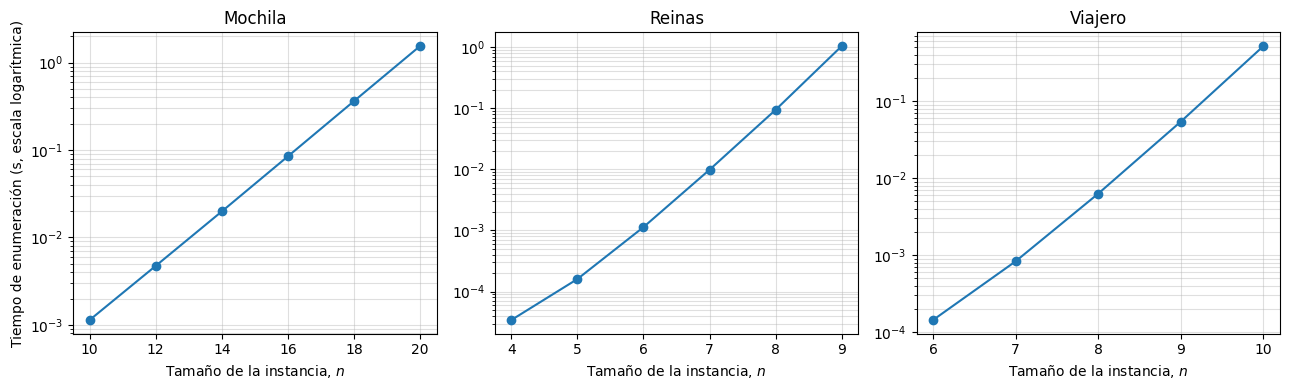

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
for eje, (nombre, datos) in zip(ejes, tiempos.items()):
    ns = [d[0] for d in datos]
    ts = [d[2] for d in datos]
    eje.semilogy(ns, ts, 'o-')
    eje.set_xlabel('Tamaño de la instancia, $n$')
    eje.set_title(nombre.capitalize())
    eje.grid(True, which='both', alpha=0.4)
ejes[0].set_ylabel('Tiempo de enumeración (s, escala logarítmica)')
plt.tight_layout()
plt.show()

En escala logarítmica, el tiempo de la mochila crece casi en línea recta, porque cada objeto adicional duplica el número de soluciones. En las reinas y el agente viajero la pendiente aumenta poco a poco, porque pasar de $n$ a $n+1$ multiplica el número de permutaciones por $n+1$ o por $n$, un factor que crece con el tamaño.

Con el tiempo medio por solución de la instancia más grande de cada problema se puede estimar cuánto tardaría la enumeración de las instancias que usa el libro. La estimación es optimista, porque evaluar una solución cuesta más cuando la instancia es más grande.

In [8]:
segundos_por_anio = 365.25 * 24 * 3600
for nombre, n_grande, total in [("mochila", 50, 2.0 ** 50),
                                ("reinas", 30, float(math.factorial(30))),
                                ("viajero", 50, float(math.factorial(49)))]:
    n, evaluadas, t = tiempos[nombre][-1]
    por_solucion = t / evaluadas
    estimado = total * por_solucion
    print(f"{nombre.capitalize():8s}: {por_solucion * 1e6:5.2f} microsegundos por solución; "
          f"enumerar n = {n_grande} tomaría unos {estimado / segundos_por_anio:.1e} años")

Mochila :  1.48 microsegundos por solución; enumerar n = 50 tomaría unos 5.3e+01 años
Reinas  :  2.87 microsegundos por solución; enumerar n = 30 tomaría unos 2.4e+19 años
Viajero :  1.43 microsegundos por solución; enumerar n = 50 tomaría unos 2.8e+49 años


Enumerar la mochila de 50 objetos tomaría unas cinco décadas, y las otras dos enumeraciones, más de $10^{19}$ años. Los métodos exactos más elaborados resuelven instancias mucho mayores que la enumeración, pero el crecimiento de fondo no desaparece, y en problemas reales, con miles de variables o con funciones objetivo costosas de evaluar, hace falta otra estrategia.

Las enumeraciones dejan además dos resultados que se usan en el resto del capítulo y en los siguientes. El valor óptimo de la mochila de 20 objetos y la longitud mínima del recorrido por las 10 primeras ciudades sirven como referencia para medir qué tan lejos queda una heurística del óptimo. En las reinas, la enumeración muestra que en el tablero de $8 \times 8$ solo 92 de las 40 320 permutaciones no tienen conflictos.

In [9]:
print(f"Mochila de 20 objetos: valor óptimo {optimo_mochila}, objetos {[i for i, xi in enumerate(x_optima) if xi]}")
print(f"Viajero de 10 ciudades: longitud mínima {optimo_viajero:.2f}, recorrido {list(ruta_optima)}")

Mochila de 20 objetos: valor óptimo 402, objetos [0, 3, 4, 5, 8, 11, 12, 13, 15, 16, 19]
Viajero de 10 ciudades: longitud mínima 223.07, recorrido [0, 9, 6, 5, 3, 8, 1, 4, 2, 7]


## Muestreo aleatorio

La alternativa más simple a la enumeración es el muestreo aleatorio (*random sampling*): generar soluciones al azar, de manera uniforme en el espacio de soluciones, evaluarlas y quedarse con la mejor. No necesita ordenar las soluciones ni recorrerlas todas, y se detiene cuando se agota el presupuesto de evaluaciones. Tampoco aprovecha nada de lo que aprende al evaluar, porque cada solución se genera sin mirar las anteriores.

La celda siguiente toma 10 000 soluciones al azar de cada problema: vectores binarios uniformes para la mochila de 20 objetos, permutaciones uniformes para el tablero de $8 \times 8$ y recorridos uniformes por las 10 primeras ciudades. En los tres casos se conoce el óptimo gracias a la enumeración.

In [10]:
np.random.seed(42)
random.seed(42)
num_muestras = 10000

# Mochila: vectores binarios uniformes
muestras_mochila = [valor_mochila(np.random.randint(0, 2, size=N_OBJETOS), pesos, valores, capacidad)
                    for _ in range(num_muestras)]
factibles = [v for v in muestras_mochila if v is not None]

# Reinas: permutaciones uniformes del tablero de 8 x 8
muestras_reinas = [conflictos(np.random.permutation(8)) for _ in range(num_muestras)]

# Viajero: recorridos uniformes por las 10 primeras ciudades
d10 = distancias[:10, :10]
muestras_viajero = [longitud_recorrido(np.random.permutation(10), d10) for _ in range(num_muestras)]

print(f"Mochila: {len(factibles)} de {num_muestras} muestras factibles; mejor valor {max(factibles)} "
      f"frente al óptimo {optimo_mochila}")
print(f"Reinas:  {sum(c == 0 for c in muestras_reinas)} de {num_muestras} muestras sin conflictos; "
      f"conflictos promedio {np.mean(muestras_reinas):.2f}")
print(f"Viajero: mejor longitud {min(muestras_viajero):.2f} frente al óptimo {optimo_viajero:.2f}; "
      f"longitud promedio {np.mean(muestras_viajero):.2f}")

Mochila: 2154 de 10000 muestras factibles; mejor valor 380 frente al óptimo 402
Reinas:  27 de 10000 muestras sin conflictos; conflictos promedio 5.02
Viajero: mejor longitud 250.67 frente al óptimo 223.07; longitud promedio 458.80


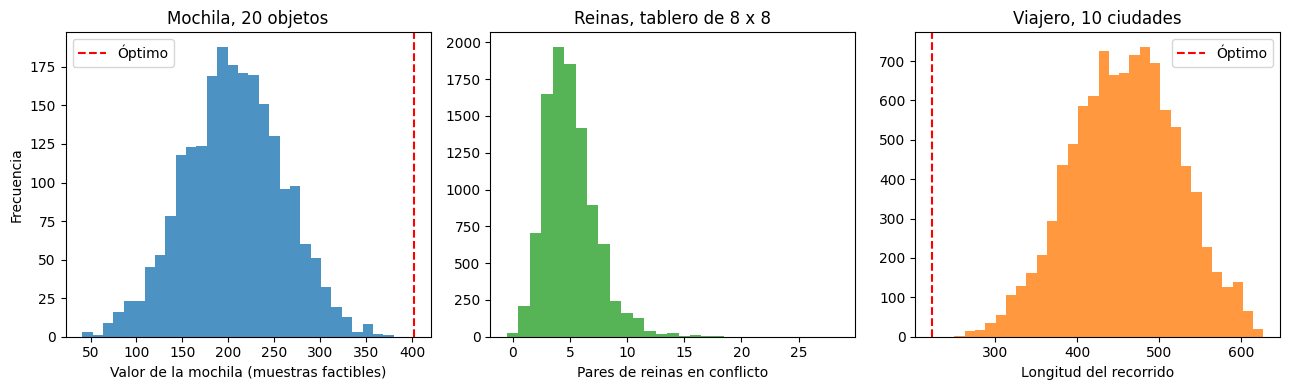

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))

ejes[0].hist(factibles, bins=30, color='tab:blue', alpha=0.8)
ejes[0].axvline(optimo_mochila, color='red', linestyle='--', label='Óptimo')
ejes[0].set_xlabel('Valor de la mochila (muestras factibles)')
ejes[0].set_ylabel('Frecuencia')
ejes[0].set_title('Mochila, 20 objetos')
ejes[0].legend()

ejes[1].hist(muestras_reinas, bins=np.arange(-0.5, max(muestras_reinas) + 1.5), color='tab:green', alpha=0.8)
ejes[1].set_xlabel('Pares de reinas en conflicto')
ejes[1].set_title('Reinas, tablero de 8 x 8')

ejes[2].hist(muestras_viajero, bins=30, color='tab:orange', alpha=0.8)
ejes[2].axvline(optimo_viajero, color='red', linestyle='--', label='Óptimo')
ejes[2].set_xlabel('Longitud del recorrido')
ejes[2].set_title('Viajero, 10 ciudades')
ejes[2].legend()

plt.tight_layout()
plt.show()

El muestreo aleatorio no llega al óptimo en ninguno de los tres problemas. En la mochila, solo cerca de una de cada cinco muestras cabe en la capacidad, y la mejor de ellas vale 380, frente al óptimo de 402. El histograma muestra por qué. Una selección al azar incluye en promedio la mitad de los objetos, y las selecciones factibles se concentran alrededor de 200, lejos del óptimo; las soluciones buenas están en la cola derecha de la distribución, donde caen muy pocas muestras.

En las reinas, 27 de las 10 000 permutaciones no tienen conflictos, una proporción cercana a la que da la enumeración, 92 de 40 320. Encontrar una solución del tablero de $8 \times 8$ al azar es posible, pero la enumeración muestra que la proporción de permutaciones sin conflictos baja con el tamaño del tablero, de 2 en 24 con $n = 4$ a 352 en 362 880 con $n = 9$, y en el tablero de $30 \times 30$ el muestreo aleatorio deja de ser una opción. En el agente viajero, el mejor de los 10 000 recorridos mide 250,67, un 12 % más que el óptimo, aunque la muestra equivale a cerca del 5,5 % de los 181 440 recorridos distintos. La longitud promedio de un recorrido al azar, 458,80, duplica la del óptimo.

## Mapa del libro

Los capítulos siguientes presentan maneras de aprovechar la información que el muestreo aleatorio desperdicia. Casi todas parten de una misma idea: una solución buena suele estar cerca de otras soluciones buenas, de modo que tiene sentido buscar alrededor de las mejores soluciones encontradas en lugar de saltar al azar. Para eso hace falta definir qué significa que dos soluciones estén cerca, y la manera de hacerlo depende de cómo se representa la solución.

El libro está organizado en cuatro partes.

- La primera parte, de fundamentos, reúne este capítulo; el capítulo 2, sobre la representación de las soluciones y las medidas de distancia entre ellas; el capítulo 3, sobre las heurísticas constructivas, la búsqueda local y el problema de los óptimos locales, y el capítulo 4, sobre las primeras estrategias para salir de ellos, los reinicios aleatorios, la búsqueda local iterada y GRASP.
- La segunda parte presenta los métodos de trayectoria, que mejoran una sola solución a lo largo de la búsqueda: la búsqueda tabú (capítulo 5), la búsqueda de vecindad variable (capítulo 6), el recocido simulado (capítulo 7) y la búsqueda en vecindarios grandes (capítulo 8).
- La tercera parte presenta los métodos poblacionales, que trabajan con un conjunto de soluciones que se combinan entre sí: los algoritmos genéticos (capítulo 9), la colonia de hormigas (capítulo 10), la optimización por enjambre de partículas (capítulo 11), la búsqueda dispersa (capítulo 12) y los algoritmos meméticos (capítulo 13), que añaden búsqueda local a un algoritmo genético.
- La cuarta parte va más allá de un objetivo y una corrida, con la optimización multiobjetivo (capítulo 14), el ajuste de los parámetros de una metaheurística (capítulo 15) y la comparación estadística de algoritmos (capítulo 16).